# Taller: Psicología del color, accesibilidad visual y legibilidad
**Universidad Externado de Colombia — Ciencia de Datos — Visualización I**

**Nombre:** _________________________

### Situación comunicativa
Una entidad distrital necesita mostrar en una reunión ejecutiva **cuál localidad registra el mayor número de hurtos** y cómo se compara con las demás.

| Localidad | Hurtos |
|---|---|
| Kennedy | 540 |
| Suba | 480 |
| Engativá | 390 |
| Bosa | 360 |
| Usaquén | 220 |

Este notebook resuelve los 4 puntos del taller aplicando conceptos de **teoría del color** y **Gestalt**, no solo código. Cada celda de código está comentada explicando la decisión de diseño detrás.

## 1. Elección del gráfico

**Gráfico elegido:** barras horizontales.

**Justificación (una frase):** las barras horizontales permiten comparar valores mediante longitud de forma precisa y leer los nombres de las localidades sin rotar el texto, lo que mejora la legibilidad frente a un gráfico circular.

In [1]:
# Instalar/asegurar matplotlib (en Colab normalmente ya viene preinstalado)
import matplotlib.pyplot as plt

# -----------------------------------------------------------------------
# DATOS
# -----------------------------------------------------------------------
# Se ordenan de mayor a menor de forma intencional: esto aplica el
# principio de orden/SIMILITUD de Gestalt, ya que un ranking descendente
# se compara y se lee más rápido que datos en orden alfabético.
localidades = ["Kennedy", "Suba", "Engativá", "Bosa", "Usaquén"]
hurtos = [540, 480, 390, 360, 220]

datos = sorted(zip(localidades, hurtos), key=lambda x: x[1], reverse=True)
localidades_ordenadas = [d[0] for d in datos]
valores_ordenados = [d[1] for d in datos]

localidades_ordenadas, valores_ordenados

(['Kennedy', 'Suba', 'Engativá', 'Bosa', 'Usaquén'], [540, 480, 390, 360, 220])

## 3. Psicología del color

El color se usa para **guiar la atención**, no para decorar:

- **Rojo (alerta/urgencia):** se aplica únicamente a la localidad con más hurtos (Kennedy), porque culturalmente el rojo se asocia a peligro y urgencia — coherente con el mensaje que la entidad quiere comunicar.
- **Gris neutro:** para el resto de localidades, ya que no compite por atención visual y deja que el ojo vaya directo a la barra roja.

Esto también es el principio de Gestalt de **Figura-Fondo (F)**: una figura (Kennedy) se destaca claramente sobre un fondo homogéneo (las demás barras).

In [2]:
# -----------------------------------------------------------------------
# COLOR CON SIGNIFICADO
# -----------------------------------------------------------------------
COLOR_ALERTA = "#C0392B"   # rojo ladrillo: transmite urgencia sin ser un rojo "chillón"
COLOR_NEUTRO = "#B0B0B0"   # gris neutro: bajo contraste, no distrae

colores = [COLOR_ALERTA if loc == "Kennedy" else COLOR_NEUTRO
           for loc in localidades_ordenadas]
colores

['#C0392B', '#B0B0B0', '#B0B0B0', '#B0B0B0', '#B0B0B0']

## 2. Boceto (gráfico de barras horizontal) y 3. Aplicación de Gestalt

Se construye el gráfico aplicando:

- **P (Proximidad):** se elimina el eje X y bordes innecesarios para que las 5 barras se perciban como un solo conjunto comparable.
- **S (Similitud):** las barras no destacadas comparten el mismo color gris, agrupándolas visualmente como "el resto".
- **F (Figura-fondo):** la barra roja de Kennedy resalta como figura principal sobre el fondo gris de las demás.

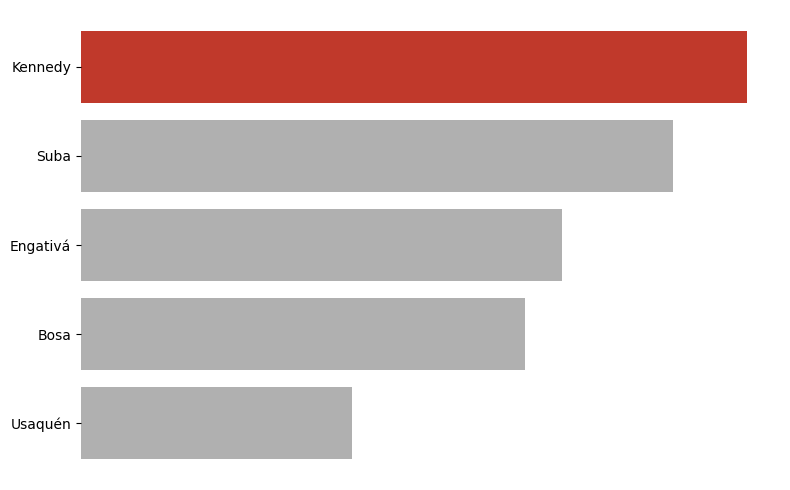

In [3]:
fig, ax = plt.subplots(figsize=(8, 5))

# barh dibuja las barras horizontales; invertimos el eje Y para que la
# barra más alta (Kennedy) quede arriba, como se lee un ranking.
barras = ax.barh(localidades_ordenadas, valores_ordenados, color=colores)
ax.invert_yaxis()

# Gestalt - Proximidad (P): quitamos ejes/bordes sobrantes para que las
# barras se perciban como un solo bloque, no como elementos sueltos.
for spine in ["top", "right", "left"]:
    ax.spines[spine].set_visible(False)
ax.spines["bottom"].set_visible(False)
ax.get_xaxis().set_visible(False)  # el valor va como etiqueta directa (accesibilidad)

plt.tight_layout()
plt.show()

## 4. Accesibilidad (mínimo 2 recursos que NO dependan del color)

- **Recurso 1 — Etiqueta directa:** el valor numérico se escribe al final de cada barra, así una persona con daltonismo puede identificar el valor más alto simplemente leyendo el número.
- **Recurso 2 — Negrilla + símbolo:** el nombre y valor de la barra destacada se muestran en negrilla y con un símbolo de alerta "▲", reforzando la jerarquía sin depender de percibir el color rojo.

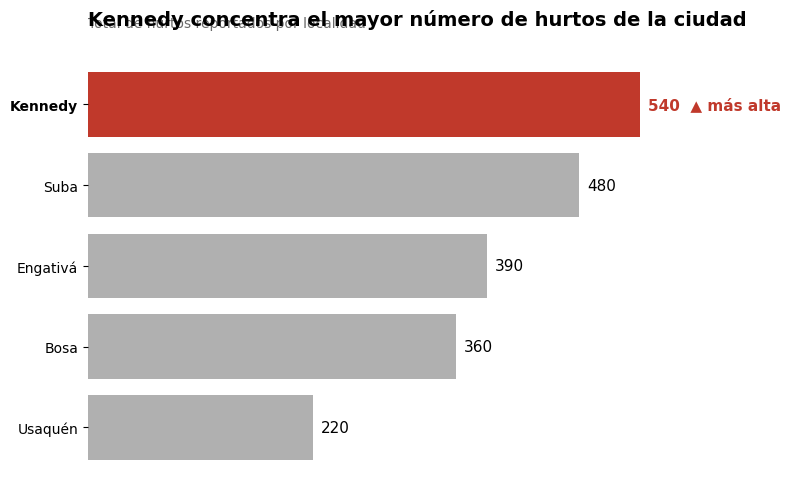

Gráfico generado: hurtos_por_localidad.png


In [4]:
fig, ax = plt.subplots(figsize=(8, 5))
barras = ax.barh(localidades_ordenadas, valores_ordenados, color=colores)
ax.invert_yaxis()

for spine in ["top", "right", "left"]:
    ax.spines[spine].set_visible(False)
ax.spines["bottom"].set_visible(False)
ax.get_xaxis().set_visible(False)

# -----------------------------------------------------------------------
# ACCESIBILIDAD: etiqueta directa + negrilla/símbolo (no dependen del color)
# -----------------------------------------------------------------------
for i, (loc, val) in enumerate(zip(localidades_ordenadas, valores_ordenados)):
    es_destacada = (loc == "Kennedy")
    etiqueta = f"{val}" + ("  ▲ más alta" if es_destacada else "")
    ax.text(
        val + 8, i, etiqueta,
        va="center",
        fontsize=11,
        fontweight="bold" if es_destacada else "normal",
        color=COLOR_ALERTA if es_destacada else "black",
    )

# Negrilla también en la etiqueta de categoría destacada (refuerzo del recurso 2)
for tick_label in ax.get_yticklabels():
    if tick_label.get_text() == "Kennedy":
        tick_label.set_fontweight("bold")

# -----------------------------------------------------------------------
# TÍTULO COMUNICATIVO
# -----------------------------------------------------------------------
# No describe el gráfico ("Hurtos por localidad"), sino que comunica el
# hallazgo principal (técnica de titulares "so-what" de Cairo / Nussbaumer Knaflic).
ax.set_title(
    "Kennedy concentra el mayor número de hurtos de la ciudad",
    fontsize=14, fontweight="bold", loc="left", pad=20
)
ax.text(
    0, 1.06, "Total de hurtos reportados por localidad",
    transform=ax.transAxes, fontsize=10, color="dimgray"
)

plt.tight_layout()
plt.savefig("hurtos_por_localidad.png", dpi=200, bbox_inches="tight")
plt.show()

print("Gráfico generado: hurtos_por_localidad.png")

### (Opcional) Descargar la imagen en Google Colab
Ejecuta la siguiente celda si quieres descargar el PNG generado a tu computador.

In [5]:
from google.colab import files
files.download("hurtos_por_localidad.png")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>